# Summative Lab: Classification, Recommendation and Clustering with PCA
**DataVine Analytics – prototype ML solutions for three client projects**

| # | Client | Dataset | Technique |
|---|---|---|---|
| 1 | Premium wine distributor | Wine | k-NN classification + PCA + GridSearchCV |
| 2 | Agricultural supply company | Chickwts | Recommendation system with PCA + cosine similarity |
| 3 | Public-safety analysis | USArrests | K-Means and Gaussian Mixture Model clustering + PCA |

The work follows the **CRISP-DM** process (Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment). Full CRISP-DM notes are in `README.md`.

## Setup: libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Step 1: Load and Prepare Datasets
*CRISP-DM: Data Understanding and Data Preparation*

### 1.1 Load the three datasets

In [2]:
wine = pd.read_csv("wine.csv")
chick = pd.read_csv("chickwts.csv")
arrests = pd.read_csv("USArrests.csv").rename(columns={"rownames": "State"}).set_index("State")
# The wine target is stored as numbers 0/1/2; give each class a readable cultivar name
wine["cultivar"] = wine["target"].map({0: "class_0", 1: "class_1", 2: "class_2"})
wine = wine.drop(columns="target")
for name, df in {"Wine": wine, "Chickwts": chick, "USArrests": arrests}.items():
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")

Wine: 178 rows x 14 columns
Chickwts: 71 rows x 2 columns
USArrests: 50 rows x 4 columns


### 1.2 Inspect for missing values, duplicates and data types

In [3]:
for name, df in {"Wine": wine, "Chickwts": chick, "USArrests": arrests}.items():
    print(f"\n===== {name} =====")
    print("Missing values in total:", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))
    print(df.dtypes.value_counts().to_string())


===== Wine =====
Missing values in total: 0
Duplicate rows: 0
float64    13
object      1

===== Chickwts =====
Missing values in total: 0
Duplicate rows: 1
int64     1
object    1

===== USArrests =====
Missing values in total: 0
Duplicate rows: 0
float64    2
int64      2


### 1.3 Summarise each dataset to confirm its structure
**Wine** – 178 wines, 13 numeric chemical measurements, 3 cultivar classes.

In [4]:
wine.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


**Chickwts** – 71 chicks, one numeric column (`weight` in grams after six weeks) and one categorical column (`feed`, 6 types).

In [5]:
print(chick["feed"].value_counts().to_string())
chick.groupby("feed")["weight"].describe().round(1).sort_values("mean", ascending=False)

feed
soybean      14
linseed      12
sunflower    12
casein       12
meatmeal     11
horsebean    10


,count,mean,std,min,25%,50%,75%,max
feed,,,,,,,,
sunflower,12.0,328.9,48.8,226.0,312.8,328.0,340.2,423.0
casein,12.0,323.6,64.4,216.0,277.2,342.0,370.8,404.0
meatmeal,11.0,276.9,64.9,153.0,249.5,263.0,320.0,380.0
soybean,14.0,246.4,54.1,158.0,206.8,248.0,270.0,329.0
linseed,12.0,218.8,52.2,141.0,178.0,221.0,257.8,309.0
horsebean,10.0,160.2,38.6,108.0,137.0,151.5,176.2,227.0


**USArrests** – 50 US states; arrests per 100,000 residents for Murder, Assault and Rape, plus `UrbanPop` (% of population living in urban areas).

In [6]:
arrests.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Murder,50.0,7.79,4.36,0.8,4.08,7.25,11.25,17.4
Assault,50.0,170.76,83.34,45.0,109.00,159.00,249.00,337.0
UrbanPop,50.0,65.54,14.47,32.0,54.50,66.00,77.75,91.0
Rape,50.0,21.23,9.37,7.3,15.08,20.10,26.18,46.0


### 1.4 Handle inconsistencies
None of the datasets has missing values. The checks below tidy the text labels and confirm that values fall in sensible ranges.

The single duplicate row in Chickwts (two soybean chicks both weighing 248 g) is **kept**: these are two different chicks that happened to have the same weight, not a data-entry error. Removing it would throw away real data.

In [7]:
# Inconsistency checks: tidy text labels and confirm the expected value ranges
chick["feed"] = chick["feed"].str.strip().str.lower()
wine["cultivar"] = wine["cultivar"].str.strip()
print("Feed types:", sorted(chick["feed"].unique()))
print("Any negative numbers?",
      bool((wine.select_dtypes("number") < 0).any().any()
           or (chick["weight"] < 0).any()
           or (arrests < 0).any().any()))
print("UrbanPop within 0-100%?", arrests["UrbanPop"].between(0, 100).all())
print("Duplicate chickwts rows:")
print(chick[chick.duplicated(keep=False)])

Feed types: ['casein', 'horsebean', 'linseed', 'meatmeal', 'soybean', 'sunflower']
Any negative numbers? False
UrbanPop within 0-100%? True
Duplicate chickwts rows:
    weight     feed
24     248  soybean
35     248  soybean


### 1.5 Why standardisation is needed
The features are on very different scales (e.g. wine `proline` is in the hundreds, `hue` is around 1). Distance-based methods such as k-NN, PCA and K-Means would otherwise be dominated by the large-valued features. `StandardScaler` rescales each feature to mean 0 and standard deviation 1.

Each dataset is standardised inside its own step below. For the Wine model, scaling happens **inside a pipeline** so it is learned from the training data only, which avoids leaking information from the test set.

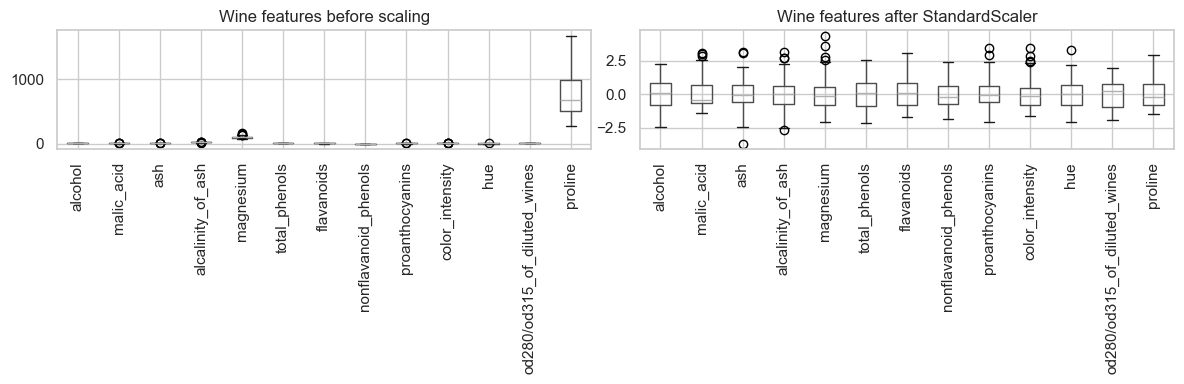

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wine.drop(columns="cultivar").boxplot(ax=axes[0], rot=90)
axes[0].set_title("Wine features before scaling")
pd.DataFrame(StandardScaler().fit_transform(wine.drop(columns="cultivar")),
             columns=wine.columns[:-1]).boxplot(ax=axes[1], rot=90)
axes[1].set_title("Wine features after StandardScaler")
plt.tight_layout(); plt.show()

# Step 2: k-NN Classification on the Wine Dataset
*CRISP-DM: Modeling and Evaluation*

**Business goal:** automatically identify the wine variety (cultivar) from its chemical properties to support inventory management and quality control.

### 2.1 Convert the categorical target labels into numbers
`LabelEncoder` turns the cultivar names into 0, 1, 2. The data is then split 80/20 into training and test sets, stratified so that each class keeps the same proportion in both.

In [9]:
le = LabelEncoder()
X_wine = wine.drop(columns="cultivar")
y_wine = le.fit_transform(wine["cultivar"])
print("Label mapping:", {c: int(i) for c, i in zip(le.classes_, le.transform(le.classes_))})
X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine, test_size=0.2, stratify=y_wine, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Label mapping: {'class_0': 0, 'class_1': 1, 'class_2': 2}
Train: (142, 13)  Test: (36, 13)


### 2.2 Apply PCA, keeping 95% of the variance
PCA combines the 13 correlated chemical measurements into fewer uncorrelated components. Passing `n_components=0.95` keeps just enough components to explain 95% of the variance.

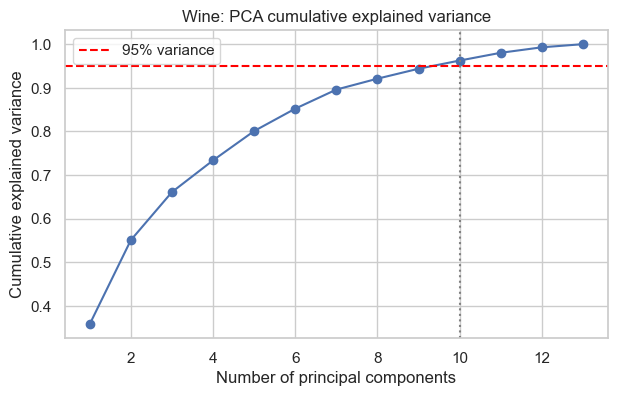

Components needed to keep 95% of the variance: 10 (out of 13)


In [10]:
scaler_w = StandardScaler().fit(X_train)
pca_check = PCA().fit(scaler_w.transform(X_train))
cum_var = np.cumsum(pca_check.explained_variance_ratio_)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="red", ls="--", label="95% variance")
plt.axvline(n_95, color="grey", ls=":")
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("Wine: PCA cumulative explained variance"); plt.legend(); plt.show()
print(f"Components needed to keep 95% of the variance: {n_95} (out of {X_wine.shape[1]})")

### 2.3 GridSearchCV to find the best k and distance metric
The pipeline is **StandardScaler → PCA (95%) → k-NN**. GridSearchCV tries every combination of:
- `n_neighbors` (k) from 1 to 21
- distance `metric`: euclidean, manhattan, chebyshev
- `weights`: uniform (every neighbour counts equally) or distance (closer neighbours count more)

and scores each combination with 5-fold stratified cross-validation on the training set.

In [11]:
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier()),
])
param_grid = {
    "knn__n_neighbors": list(range(1, 22)),
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Best cross-validated accuracy: {grid.best_score_:.3f}")
print("PCA components used by the final model:", grid.best_estimator_.named_steps["pca"].n_components_)

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 10, 'knn__weights': 'uniform'}
Best cross-validated accuracy: 0.965
PCA components used by the final model: 10


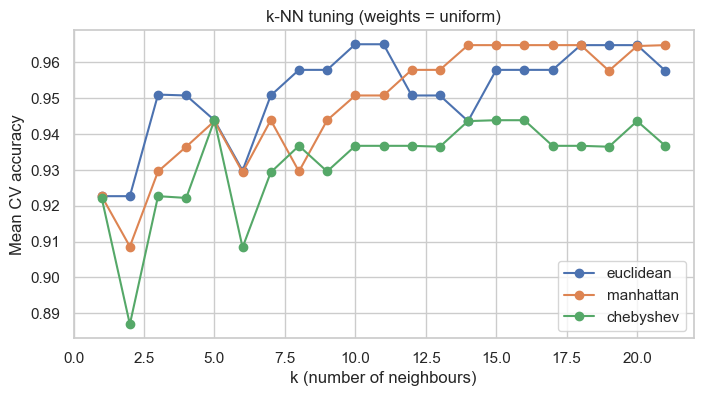

In [12]:
res = pd.DataFrame(grid.cv_results_)
res = res[res["param_knn__weights"] == grid.best_params_["knn__weights"]]
plt.figure(figsize=(8, 4))
for m in param_grid["knn__metric"]:
    sub = res[res["param_knn__metric"] == m]
    plt.plot(sub["param_knn__n_neighbors"], sub["mean_test_score"], marker="o", label=m)
plt.xlabel("k (number of neighbours)"); plt.ylabel("Mean CV accuracy")
plt.title(f"k-NN tuning (weights = {grid.best_params_['knn__weights']})"); plt.legend(); plt.show()

### 2.4 Train the k-NN classifier with the best parameters and evaluate it

In [13]:
best_p = {k.replace("knn__", ""): v for k, v in grid.best_params_.items()}
final_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(**best_p)),
])
final_knn.fit(X_train, y_train)
y_pred = final_knn.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Test accuracy: 1.000

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



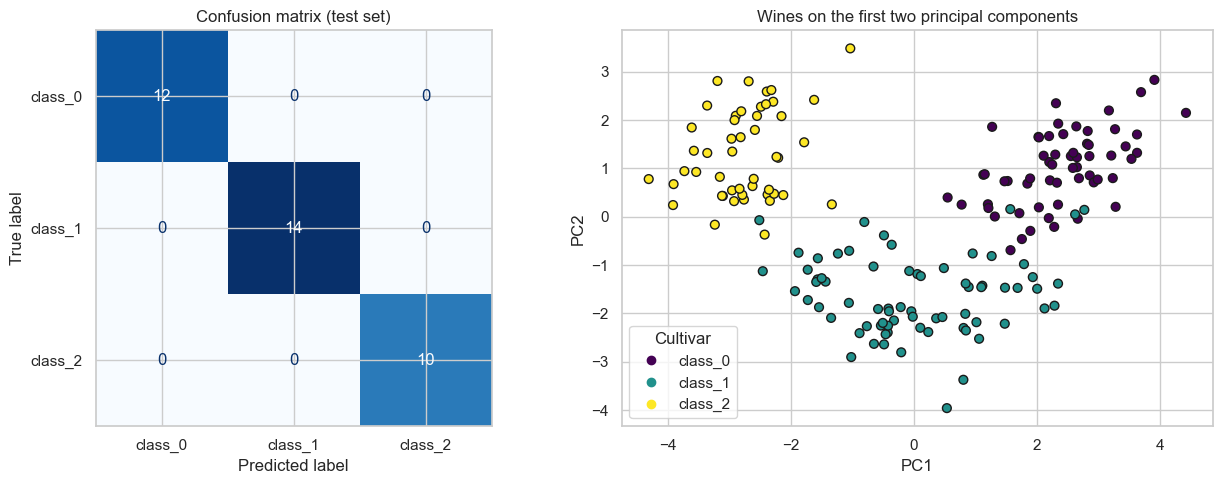

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test set)")
Z = final_knn[:-1].transform(X_wine)
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=y_wine, cmap="viridis", edgecolor="k", s=40)
axes[1].legend(sc.legend_elements()[0], le.classes_, title="Cultivar")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Wines on the first two principal components")
plt.tight_layout(); plt.show()

### 2.5 Interpretation for the wine distributor
- PCA reduced 13 measurements to **10 components** while keeping 95% of the information.
- The tuned model (**k = 10, Euclidean distance, uniform weights**) reached about **96.5% cross-validated accuracy** and classified **all 36 unseen test wines correctly**.
- The PCA scatter plot shows why: the three cultivars form clearly separated groups, so a neighbour-based method works very well.
- **Caution:** a perfect score on 36 test wines is encouraging but optimistic. The cross-validated 96.5% is a more realistic estimate of performance on new stock.

# Step 3: Recommendation System Using the Chickwts Dataset
*CRISP-DM: Modeling and Evaluation*

**Business goal:** recommend feed types that produce similar results to a farmer's current feed.

### 3.1 Standardise the weight feature

In [15]:
chick["weight_scaled"] = StandardScaler().fit_transform(chick[["weight"]])
print(chick["weight_scaled"].describe().round(3))

count    71.000
mean     -0.000
std       1.007
min      -1.978
25%      -0.733
50%      -0.043
75%       0.802
max       2.086
Name: weight_scaled, dtype: float64


### 3.2 Apply PCA to reduce to one principal component
With only one numeric feature, the single component carries 100% of the variance and is simply the standardised weight (the sign is fixed so that higher = heavier). It is included as the required step and keeps the pipeline ready for extra performance measures (e.g. feed cost or growth rate) in future.

In [16]:
pca_chick = PCA(n_components=1)
chick["pc1"] = pca_chick.fit_transform(chick[["weight_scaled"]]).ravel()
if np.corrcoef(chick["pc1"], chick["weight"])[0, 1] < 0:
    chick["pc1"] *= -1   # make "higher PC1 = heavier chicks" for readability
print("Explained variance by PC1:", pca_chick.explained_variance_ratio_.round(3))
chick.head()

Explained variance by PC1: [1.]


,weight,feed,weight_scaled,pc1
0,179,horsebean,-1.061762,-1.061762
1,160,horsebean,-1.306854,-1.306854
2,136,horsebean,-1.616444,-1.616444
3,227,horsebean,-0.442583,-0.442583
4,217,horsebean,-0.571578,-0.571578


### 3.3 Build a performance profile for each feed
Cosine similarity needs a **vector** for each feed. Each feed is described by the distribution of its PC1 scores: mean, median, spread (std), min, max and quartiles. Two feeds that produce similar typical weights *and* similar consistency will have similar profiles.

In [17]:
q25 = lambda s: s.quantile(0.25); q25.__name__ = "q25"
q75 = lambda s: s.quantile(0.75); q75.__name__ = "q75"
feed_profiles = chick.groupby("feed")["pc1"].agg(["mean", "median", "std", "min", "max", q25, q75])
feed_profiles.round(3).sort_values("mean", ascending=False)

,mean,median,std,min,max,q25,q75
feed,,,,,,,
sunflower,0.872,0.860,0.630,-0.455,2.086,0.664,1.018
casein,0.803,1.041,0.831,-0.584,1.841,0.206,1.412
meatmeal,0.201,0.022,0.837,-1.397,1.531,-0.152,0.757
soybean,-0.192,-0.172,0.698,-1.333,0.873,-0.704,0.112
linseed,-0.549,-0.520,0.674,-1.552,0.615,-1.075,-0.046
horsebean,-1.304,-1.417,0.498,-1.978,-0.443,-1.604,-1.097


### 3.4 Compute cosine similarity between feed types
A score close to **1** means very similar results, close to **0** means unrelated, and negative values mean opposite performance (one above average, the other below).

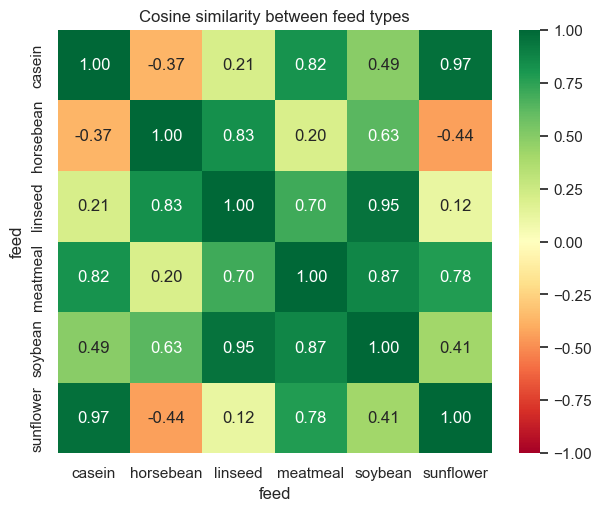

In [18]:
sim = pd.DataFrame(cosine_similarity(feed_profiles), index=feed_profiles.index, columns=feed_profiles.index)
plt.figure(figsize=(7, 5.5))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1)
plt.title("Cosine similarity between feed types"); plt.show()

### 3.5 Recommend similar feeds

In [19]:
def recommend_feeds(feed, top_n=3):
    """Return the top_n feeds most similar to `feed` by cosine similarity."""
    feed = feed.strip().lower()
    if feed not in sim.index:
        raise ValueError(f"Unknown feed '{feed}'. Choose from {list(sim.index)}")
    scores = sim[feed].drop(feed).sort_values(ascending=False).head(top_n)
    return pd.DataFrame({"recommended_feed": scores.index,
                         "similarity": scores.values.round(3),
                         "mean_weight_g": chick.groupby("feed")["weight"].mean()[scores.index].round(1).values})

for f in sim.index:
    print(f"\nFarmers using {f.upper()} could also consider:")
    print(recommend_feeds(f).to_string(index=False))


Farmers using CASEIN could also consider:
recommended_feed  similarity  mean_weight_g
       sunflower       0.968          328.9
        meatmeal       0.818          276.9
         soybean       0.488          246.4

Farmers using HORSEBEAN could also consider:
recommended_feed  similarity  mean_weight_g
         linseed       0.829          218.8
         soybean       0.627          246.4
        meatmeal       0.199          276.9

Farmers using LINSEED could also consider:
recommended_feed  similarity  mean_weight_g
         soybean       0.951          246.4
       horsebean       0.829          160.2
        meatmeal       0.696          276.9

Farmers using MEATMEAL could also consider:
recommended_feed  similarity  mean_weight_g
         soybean       0.873          246.4
          casein       0.818          323.6
       sunflower       0.781          328.9

Farmers using SOYBEAN could also consider:
recommended_feed  similarity  mean_weight_g
         linseed       0.951  

### 3.6 Interpretation for the agricultural supply company
- **Sunflower ↔ casein** are the closest pair (similarity ≈ 0.97). Both produce the heaviest chicks (≈ 324–329 g), so they can substitute for each other if one is out of stock.
- **Linseed ↔ soybean** (≈ 0.95) form a mid-range pair.
- **Meatmeal** sits between the groups and is most similar to soybean and casein.
- **Horsebean** produces the lightest chicks (≈ 160 g). Its nearest match is linseed, so a farmer who wants heavier birds should be shown the high-performing group instead.
- **Limitation:** the data is small (10–14 chicks per feed). In practice cost, availability and nutritional content should be added before making product recommendations.

# Step 4: Clustering (K-Means & GMM) on the USArrests Dataset
*CRISP-DM: Modeling and Evaluation*

**Business goal:** group US states with similar crime patterns so resources and policy can be targeted.

### 4.1 Standardise the dataset

In [20]:
scaler_a = StandardScaler()
arrests_scaled = pd.DataFrame(scaler_a.fit_transform(arrests), index=arrests.index, columns=arrests.columns)
arrests_scaled.describe().round(2).loc[["mean", "std"]]

,Murder,Assault,UrbanPop,Rape
mean,-0.00,0.00,-0.00,0.00
std,1.01,1.01,1.01,1.01


### 4.2 Select the top 3 relevant features
Features are ranked by their absolute loading on the first principal component (how much each drives the main pattern in the data), checked against their average correlation with the other features.

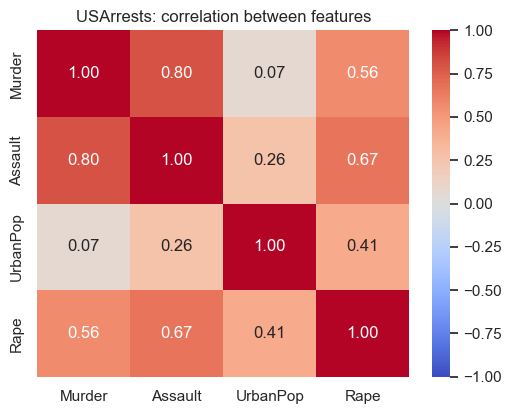

          |PC1 loading|  mean |corr| with others
Assault           0.583                    0.575
Rape              0.543                    0.547
Murder            0.536                    0.478
UrbanPop          0.278                    0.247

Top 3 features selected for clustering: ['Assault', 'Rape', 'Murder']


In [21]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(arrests.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("USArrests: correlation between features"); plt.show()
pca_full = PCA().fit(arrests_scaled)
loadings = pd.Series(np.abs(pca_full.components_[0]), index=arrests.columns, name="|PC1 loading|")
mean_abs_corr = (arrests.corr().abs().sum() - 1) / (arrests.shape[1] - 1)
ranking = pd.DataFrame({"|PC1 loading|": loadings, "mean |corr| with others": mean_abs_corr}).sort_values("|PC1 loading|", ascending=False)
print(ranking.round(3))
top3 = ranking.index[:3].tolist()
print("\nTop 3 features selected for clustering:", top3)

**Selected features: Assault, Rape and Murder.** The three crime rates are strongly related to each other and drive the main pattern in the data. `UrbanPop` has a weak link to the crime variables. It describes population, not crime, so it is left out.

### 4.3 Apply PCA to reduce to 2 principal components

In [22]:
pca_a = PCA(n_components=2, random_state=RANDOM_STATE)
X_clu = pca_a.fit_transform(arrests_scaled[top3])
pcs = pd.DataFrame(X_clu, index=arrests.index, columns=["PC1", "PC2"])
print("Explained variance ratio:", pca_a.explained_variance_ratio_.round(3),
      "| total:", pca_a.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca_a.components_.T, index=top3, columns=["PC1", "PC2"]).round(3))

Explained variance ratio: [0.786 0.153] | total: 0.939
           PC1    PC2
Assault  0.608 -0.214
Rape     0.539  0.818
Murder   0.583 -0.534


PC1 has similar positive weights on all three crimes, so it measures the **overall violent-crime level**. PC2 contrasts Rape (positive) with Murder (negative), so it separates states by the **type** of crime. Together they keep about 94% of the variance.

### 4.4 Determine the optimal number of clusters
- **Elbow method (inertia) for K-Means:** look for the point where adding a cluster stops giving a large improvement.
- **BIC for GMM:** the lowest Bayesian Information Criterion gives the best balance between fit and complexity.
- Silhouette scores are added as a supporting check (higher is better).

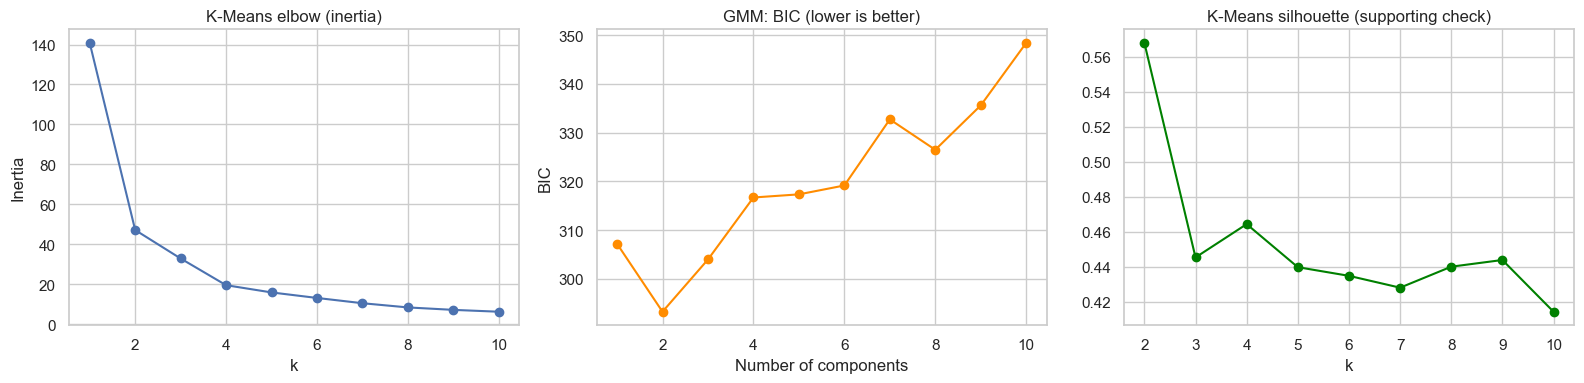

    inertia  GMM BIC  silhouette
1    140.83   307.21         NaN
2     47.12   293.28       0.568
3     32.87   303.99       0.445
4     19.51   316.70       0.464
5     15.88   317.34       0.440
6     13.12   319.16       0.435
7     10.48   332.71       0.428
8      8.37   326.48       0.440
9      7.15   335.58       0.444
10     6.22   348.40       0.414


In [23]:
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_clu).inertia_ for k in ks]
bics = [GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X_clu).bic(X_clu) for k in ks]
sils = {k: silhouette_score(X_clu, KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_clu)) for k in range(2, 11)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("K-Means elbow (inertia)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, bics, marker="o", color="darkorange"); axes[1].set_title("GMM: BIC (lower is better)"); axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("BIC")
axes[2].plot(list(sils), list(sils.values()), marker="o", color="green"); axes[2].set_title("K-Means silhouette (supporting check)"); axes[2].set_xlabel("k")
plt.tight_layout(); plt.show()
summary_k = pd.DataFrame({"inertia": np.round(inertias, 2), "GMM BIC": np.round(bics, 2)}, index=ks)
summary_k["silhouette"] = pd.Series(sils).round(3)
print(summary_k)

In [24]:
# Elbow: the k after which adding a cluster stops giving a big drop in inertia
drops = -np.diff(inertias)                      # drop gained by going k -> k+1
second = drops[:-1] - drops[1:]                 # how much the gain shrinks
k_kmeans = int(np.argmax(second) + 2)
k_gmm = int(list(ks)[int(np.argmin(bics))])
print(f"Elbow method suggests k = {k_kmeans} for K-Means")
print(f"Lowest BIC suggests {k_gmm} components for GMM")

Elbow method suggests k = 2 for K-Means
Lowest BIC suggests 2 components for GMM


All three methods agree: **2 clusters**. Inertia drops sharply from 1 to 2 clusters (140.8 → 47.1) and only gradually after that. BIC is lowest at 2 components, and the silhouette score is highest at k = 2.

### 4.5 Apply the clustering models
- **K-Means** gives each state one hard cluster label.
- **GMM** gives each state a *probability* of belonging to each cluster; `gmm_confidence` is the highest of those probabilities.

In [25]:
kmeans = KMeans(n_clusters=k_kmeans, n_init=20, random_state=RANDOM_STATE).fit(X_clu)
gmm = GaussianMixture(n_components=k_gmm, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X_clu)
results = arrests.copy()
results["kmeans_cluster"] = kmeans.labels_
results["gmm_cluster"] = gmm.predict(X_clu)
probs = gmm.predict_proba(X_clu)
results["gmm_confidence"] = probs.max(axis=1).round(3)
print("K-Means silhouette:", round(silhouette_score(X_clu, results["kmeans_cluster"]), 3))
if k_gmm > 1:
    print("GMM silhouette:   ", round(silhouette_score(X_clu, results["gmm_cluster"]), 3))
print("Agreement between the two methods (Adjusted Rand Index):",
      round(adjusted_rand_score(results["kmeans_cluster"], results["gmm_cluster"]), 3))

K-Means silhouette: 0.568
GMM silhouette:    0.561
Agreement between the two methods (Adjusted Rand Index): 0.92


### 4.6 Visualise and compare the clustering results

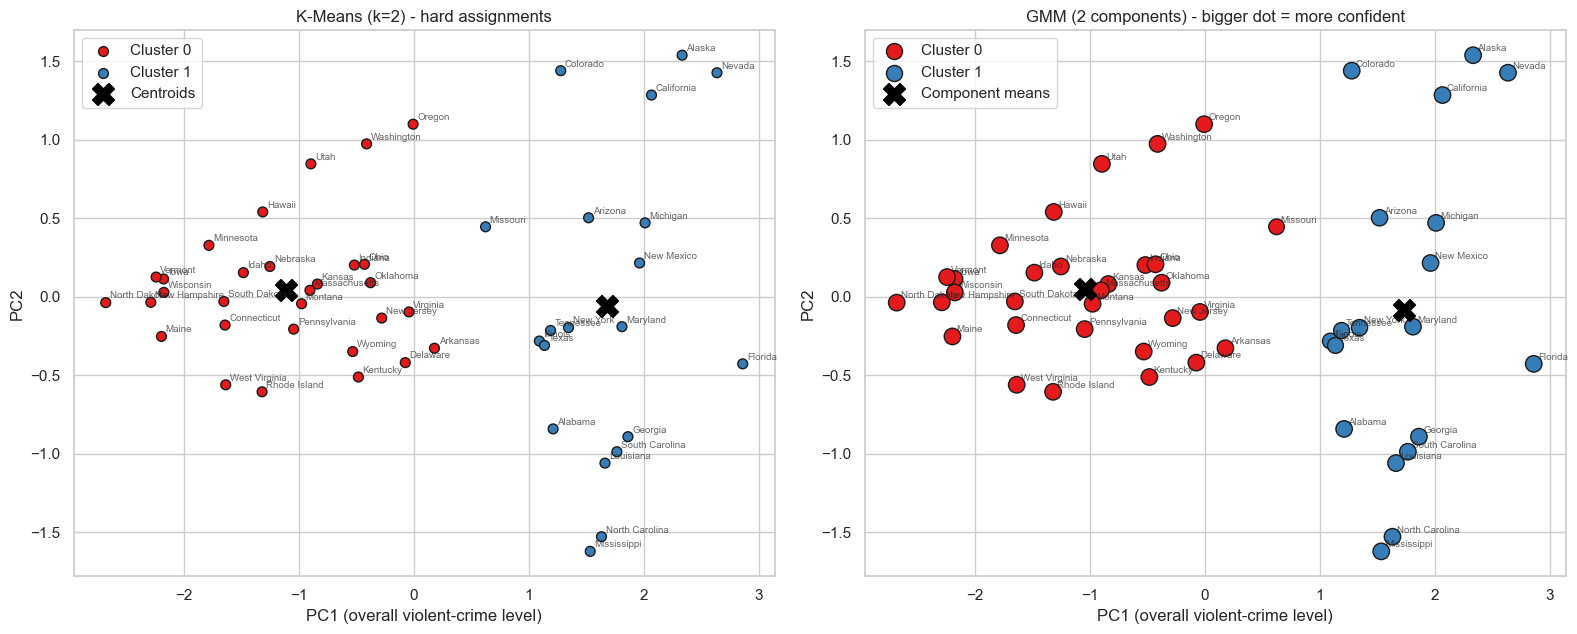

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
colors = np.array(sns.color_palette("Set1", 10))
panels = [(axes[0], "kmeans_cluster", f"K-Means (k={k_kmeans}) - hard assignments", np.full(len(results), 50)),
          (axes[1], "gmm_cluster", f"GMM ({k_gmm} components) - bigger dot = more confident", 20 + 120 * results["gmm_confidence"].values)]
for ax, col, title, sizes in panels:
    for c in sorted(results[col].unique()):
        m = (results[col] == c).values
        ax.scatter(pcs["PC1"][m], pcs["PC2"][m], s=sizes[m], color=colors[c], edgecolor="k", label=f"Cluster {c}")
    for st, (x, y) in pcs.iterrows():
        ax.annotate(st, (x, y), fontsize=7, alpha=0.7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title); ax.set_xlabel("PC1 (overall violent-crime level)"); ax.set_ylabel("PC2")
axes[0].scatter(*kmeans.cluster_centers_.T, marker="X", s=250, c="black", label="Centroids")
axes[1].scatter(*gmm.means_.T, marker="X", s=250, c="black", label="Component means")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

In [27]:
print("Average original values per K-Means cluster:")
print(results.groupby("kmeans_cluster")[arrests.columns.tolist()].mean().round(1).assign(n_states=results["kmeans_cluster"].value_counts()))
print("\nAverage original values per GMM cluster:")
print(results.groupby("gmm_cluster")[arrests.columns.tolist()].mean().round(1).assign(n_states=results["gmm_cluster"].value_counts()))
print("\nK-Means vs GMM cross-tab:")
print(pd.crosstab(results["kmeans_cluster"], results["gmm_cluster"], rownames=["K-Means"], colnames=["GMM"]))

Average original values per K-Means cluster:
                Murder  Assault  UrbanPop  Rape  n_states
kmeans_cluster                                           
0                  4.9    114.4      63.6  15.9        30
1                 12.2    255.2      68.4  29.2        20

Average original values per GMM cluster:
             Murder  Assault  UrbanPop  Rape  n_states
gmm_cluster                                           
0               5.0    116.5      63.8  16.3        31
1              12.3    259.3      68.3  29.2        19

K-Means vs GMM cross-tab:
GMM       0   1
K-Means        
0        30   0
1         1  19


In [28]:
print("States GMM is least sure about (borderline cases):")
results.sort_values("gmm_confidence")[top3 + ["kmeans_cluster", "gmm_cluster", "gmm_confidence"]].head(8)

States GMM is least sure about (borderline cases):


,Assault,Rape,Murder,kmeans_cluster,gmm_cluster,gmm_confidence
State,,,,,,
Missouri,178,28.2,9.0,1,0,0.884
Illinois,249,24.0,10.4,1,1,0.894
Texas,201,25.5,12.7,1,1,0.923
Tennessee,188,26.9,13.2,1,1,0.924
New York,254,26.1,11.1,1,1,0.964
Arizona,294,31.0,8.1,1,1,0.972
Arkansas,190,19.5,8.8,0,0,0.987
New Mexico,285,32.1,11.4,1,1,0.995


In [29]:
for c in sorted(results["kmeans_cluster"].unique()):
    print(f"K-Means cluster {c}:", ", ".join(results.index[results["kmeans_cluster"] == c]))

K-Means cluster 0: Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming
K-Means cluster 1: Alabama, Alaska, Arizona, California, Colorado, Florida, Georgia, Illinois, Louisiana, Maryland, Michigan, Mississippi, Missouri, Nevada, New Mexico, New York, North Carolina, South Carolina, Tennessee, Texas


### 4.7 Interpretation
- **Two clear groups:** a **higher-crime cluster** (about 20 states, e.g. Florida, Nevada, California, Maryland) with roughly 2.5× the murder rate and more than 2× the assault rate of the **lower-crime cluster** (about 30 states, e.g. Maine, North Dakota, Vermont).
- **K-Means vs GMM:** the two methods agree on 49 of 50 states (Adjusted Rand Index ≈ 0.92). The only difference is **Missouri**, a borderline state that K-Means puts in the higher-crime group while GMM leans towards the lower-crime group.
- **Added value of GMM:** its probabilities flag borderline states (Missouri, Illinois, Texas, Tennessee) where a hard label could be misleading. These deserve closer, case-by-case review rather than a blanket policy.
- Urbanisation was deliberately excluded, so the clusters reflect crime levels alone.

# Conclusions and Recommendations
*CRISP-DM: Evaluation and Deployment*

| Project | Result | Recommendation |
|---|---|---|
| Wine classification | ≈ 96.5% CV accuracy, 100% on the test set, using 10 PCA components | Ready for a pilot in quality control. Keep monitoring accuracy as new batches arrive. |
| Feed recommendation | Clear similarity groups: {sunflower, casein}, {linseed, soybean}, with meatmeal between them and horsebean lowest | Use as a "similar products" feature. Add cost and nutrition data before going live. |
| Crime clustering | 2 robust clusters; K-Means and GMM agree on 49 of 50 states | Use the clusters to prioritise resources. Use GMM probabilities to flag borderline states. |

**Shared lessons:** standardising the data was essential for every distance-based method. PCA reduced dimensionality with little loss of information and made the results easy to visualise. Cross-validated tuning (GridSearchCV, elbow, BIC) gave evidence-based parameter choices instead of guesses.